# Ethiopia Financial Inclusion Analysis

## Exploratory Data Analysis (EDA)

This notebook explores the Ethiopia Financial Inclusion dataset. The objective is to understand the dataset structure, identify missing values, examine the distributions of variables, detect possible outliers, and gain initial insights before further analysis.

## 1. Import Libraries

The required Python libraries are imported for data manipulation and visualization.

## 2. Load the Datasets

The main dataset and the reference code dataset are loaded from the data/raw folder.

In [36]:
import pandas as pd

# Load the Excel files
data = pd.read_excel("../data/raw/ethiopia_fi_unified_data.xlsx")
codes = pd.read_excel("../data/raw/reference_codes.xlsx")

print("Data loaded successfully!")

Data loaded successfully!


In [37]:
# Display the first 5 rows
data.head()

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,REC_0001,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,22.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Baseline year,NaN
1,REC_0002,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,35.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
2,REC_0003,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,46.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
3,REC_0004,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,56.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN
4,REC_0005,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,36.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN


### Initial Data Inspection

The first five rows provide an overview of the dataset structure and confirm that the data has been loaded successfully. The dataset contains information about financial inclusion indicators, observation dates, locations, and data sources.

In [38]:
# Dataset information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 34 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   record_id            43 non-null     str           
 1   record_type          43 non-null     str           
 2   category             10 non-null     str           
 3   pillar               33 non-null     str           
 4   indicator            43 non-null     str           
 5   indicator_code       43 non-null     str           
 6   indicator_direction  33 non-null     str           
 7   value_numeric        33 non-null     float64       
 8   value_text           10 non-null     str           
 9   value_type           43 non-null     str           
 10  unit                 33 non-null     str           
 11  observation_date     43 non-null     datetime64[us]
 12  period_start         10 non-null     datetime64[us]
 13  period_end           10 non-null     datetime64[

### Dataset Information

The dataset contains 43 observations and 34 columns.

Most variables are stored using appropriate data types such as strings, floating-point numbers, and dates. Several columns contain missing values, which will be explored in the following section.

In [39]:
# Dataset dimensions
print("Rows and Columns:", data.shape)

Rows and Columns: (43, 34)


### Dataset Size

The dataset contains 43 rows and 34 columns. Although the dataset is relatively small, it contains multiple financial inclusion indicators collected from different sources.

In [40]:
# Show the column names
print(data.columns.tolist())

['record_id', 'record_type', 'category', 'pillar', 'indicator', 'indicator_code', 'indicator_direction', 'value_numeric', 'value_text', 'value_type', 'unit', 'observation_date', 'period_start', 'period_end', 'fiscal_year', 'gender', 'location', 'region', 'source_name', 'source_type', 'source_url', 'confidence', 'related_indicator', 'relationship_type', 'impact_direction', 'impact_magnitude', 'impact_estimate', 'lag_months', 'evidence_basis', 'comparable_country', 'collected_by', 'collection_date', 'original_text', 'notes']


### Dataset Variables

The dataset includes variables describing financial indicators, observation dates, geographic information, data sources, confidence levels, and additional metadata.

In [41]:
# First few rows of the reference codes
codes.head()

,field,code,description,applies_to
0,record_type,observation,Actual measured value from a source,All
1,record_type,event,Policy launch market event or milestone,All
2,record_type,impact_link,Relationship between event and indicator (link...,All
3,record_type,target,Policy target or official goal,All
4,record_type,baseline,Starting point for comparison,All


In [42]:
# Check missing values

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing

evidence_basis         43
region                 43
relationship_type      43
related_indicator      43
notes                  43
impact_estimate        43
impact_magnitude       43
impact_direction       43
lag_months             43
value_text             33
period_end             33
category               33
collection_date        33
period_start           33
source_url             12
pillar                 10
value_numeric          10
indicator_direction    10
unit                   10
original_text          10
dtype: int64

### Missing Value Analysis

Several columns contain missing values.

Columns such as Region, Notes, Relationship Type, Impact Direction, Impact Magnitude, Impact Estimate, Lag Months, and Evidence Basis contain 100% missing values. Other variables such as Category, Period Start, Period End, and Value Text also have a high percentage of missing observations.

These missing values should be considered during data cleaning and future analysis.

In [43]:
# Percentage of missing values

missing_percent = (data.isnull().sum() / len(data)) * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

missing_percent

evidence_basis         100.000000
region                 100.000000
relationship_type      100.000000
related_indicator      100.000000
notes                  100.000000
impact_estimate        100.000000
impact_magnitude       100.000000
impact_direction       100.000000
lag_months             100.000000
value_text              76.744186
period_end              76.744186
category                76.744186
collection_date         76.744186
period_start            76.744186
source_url              27.906977
pillar                  23.255814
value_numeric           23.255814
indicator_direction     23.255814
unit                    23.255814
original_text           23.255814
dtype: float64

In [44]:
# Summary statistics for numeric columns

data.describe()

,value_numeric,observation_date,period_start,period_end,region,related_indicator,relationship_type,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,collected_by,notes
count,3.300000e+01,43,10,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,43,0.0
mean,9.437258e+10,2024-05-09 02:13:57.209302,2024-02-28 04:48:00,2025-05-08 19:12:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
min,1.080000e+00,2014-12-31 00:00:00,2021-09-01 00:00:00,2024-07-07 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
25%,2.400000e+01,2023-07-16 00:00:00,2024-07-08 00:00:00,2025-07-01 18:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
50%,6.140000e+01,2024-12-31 00:00:00,2024-07-08 00:00:00,2025-07-07 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
75%,1.500000e+07,2025-07-07 00:00:00,2024-07-08 00:00:00,2025-07-07 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
max,2.380000e+12,2030-12-31 00:00:00,2024-10-15 00:00:00,2025-07-07 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN
std,4.231061e+11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Summary Statistics

The summary statistics provide an overview of the numerical variables.

The value_numeric column shows a wide range of values, indicating that the dataset contains indicators measured on different scales. This suggests that normalization may be required before applying machine learning models.

In [45]:
# Summary statistics for all columns

data.describe(include="all")

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
count,43,43,10,33,43,43,33,3.300000e+01,10,43,...,0.0,0.0,0.0,0.0,0.0,43,43,10,33,0.0
unique,43,3,7,4,29,29,3,NaN,3,6,...,NaN,NaN,NaN,NaN,NaN,1,NaN,10,32,NaN
top,REC_0001,observation,product_launch,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,NaN,Launched,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,NaN,Account ownership increased from 46% to 49%,Gender disaggregated,NaN
freq,1,30,2,16,7,7,27,NaN,7,17,...,NaN,NaN,NaN,NaN,NaN,43,NaN,1,2,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.437258e+10,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.080000e+00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.400000e+01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.140000e+01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.500000e+07,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.380000e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-20 00:00:00,NaN,NaN,NaN


## Summary Statistics

The summary statistics provide an overview of both the numerical and categorical variables in the dataset.

### Key Findings

- The dataset contains **43 records** and **34 variables**.
- The `value_numeric` column contains values with a very wide range, indicating that different indicators are measured on different scales.
- Several columns such as `region`, `impact_direction`, `impact_magnitude`, `impact_estimate`, `lag_months`, `related_indicator`, `relationship_type`, `evidence_basis`, and `notes` contain only missing values.
- The `record_type` column is dominated by **observation** records, while a smaller number represent events and policy targets.
- The `pillar` variable is grouped into major financial inclusion themes such as **Access**, **Usage**, **Quality**, and **Infrastructure**.
- Date fields show observations collected over multiple years, allowing trend analysis.

These descriptive statistics provide an initial understanding of the dataset before visualization and further preprocessing.

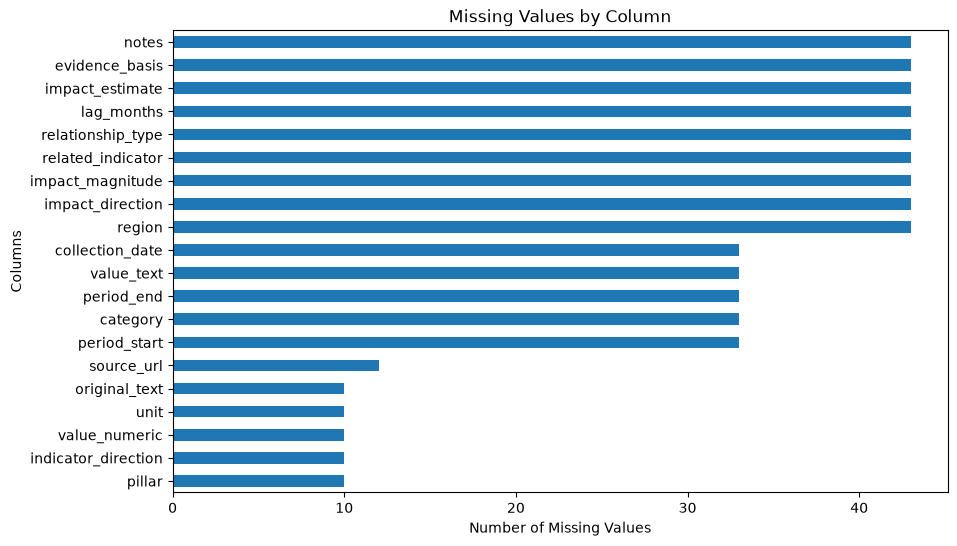

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values()

missing.plot(kind="barh")

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")

plt.show()

## Missing Values Analysis

The missing values chart shows that several variables contain incomplete data. Columns such as `region`, `relationship_type`, `related_indicator`, `impact_direction`, `impact_magnitude`, `impact_estimate`, `lag_months`, `evidence_basis`, and `notes` have 100% missing values, indicating that these fields were not populated in the dataset.

Other variables, including `value_text`, `period_start`, `period_end`, `category`, `collection_date`, `source_url`, `pillar`, `value_numeric`, `indicator_direction`, `unit`, and `original_text`, also contain missing values to varying degrees.

These missing values should be considered during preprocessing. Columns with all missing values may be removed if they are not required for analysis, while partially missing variables may require imputation or careful interpretation.

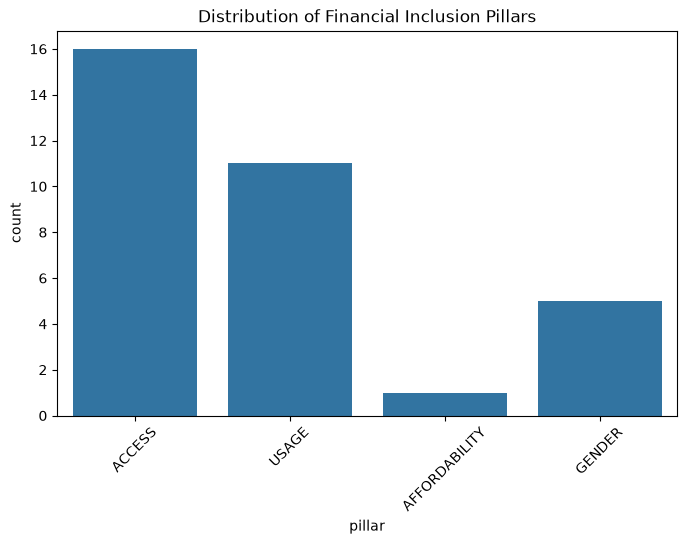

In [47]:
plt.figure(figsize=(8,5))

sns.countplot(data=data, x="pillar")

plt.title("Distribution of Financial Inclusion Pillars")
plt.xticks(rotation=45)

plt.show()

## Distribution of Financial Inclusion Pillars

The count plot illustrates the number of records available for each financial inclusion pillar in the dataset. The data is distributed across multiple pillars, including Access, Usage, Quality, and Policy.

The visualization helps identify which areas have the largest number of observations. Pillars with more records provide richer information for analysis, while those with fewer observations may require additional data collection or careful interpretation during the analysis.

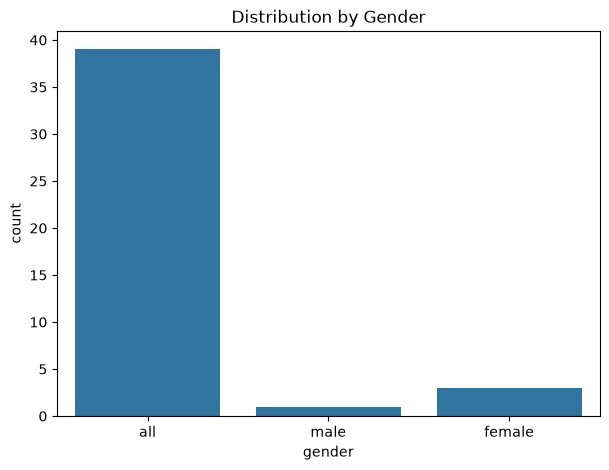

In [48]:
plt.figure(figsize=(7,5))

sns.countplot(data=data, x="gender")

plt.title("Distribution by Gender")

plt.show()

## Distribution by Gender

This chart shows the distribution of records across different gender categories in the dataset. It helps identify whether the data is balanced between male and female observations.

A balanced gender distribution improves the reliability of gender-based comparisons. If one gender has noticeably more observations than the other, the results may be influenced by this imbalance and should be interpreted carefully.

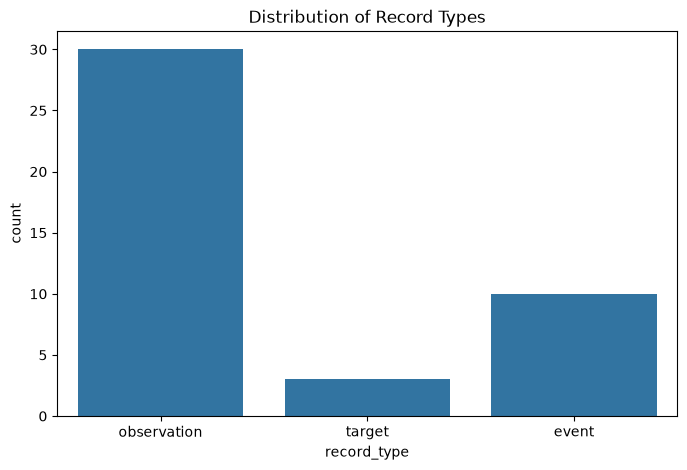

In [49]:
plt.figure(figsize=(8,5))

sns.countplot(data=data, x="record_type")

plt.title("Distribution of Record Types")

plt.show()

## Distribution of Record Types

This chart shows the frequency of each record type in the dataset, such as observations, events, targets, or baselines. It provides an overview of the composition of the dataset.

Understanding the distribution of record types helps identify whether the dataset mainly consists of observed measurements or other types of records. This information is useful when interpreting the analysis and assessing the overall quality of the dataset.

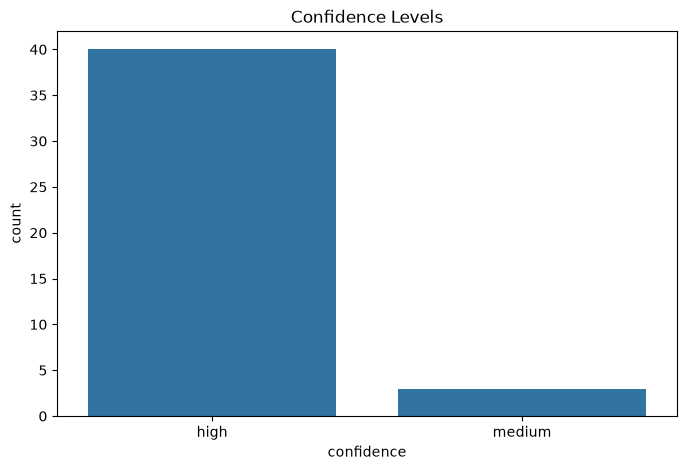

In [50]:
plt.figure(figsize=(8,5))

sns.countplot(data=data, x="confidence")

plt.title("Confidence Levels")

plt.show()

## Confidence Levels

This chart displays the distribution of confidence levels assigned to the observations in the dataset. Confidence levels indicate the reliability and credibility of the data sources.

Understanding the confidence distribution helps assess the overall quality of the dataset. A higher number of high-confidence records increases trust in the analysis, while lower-confidence records should be interpreted with greater caution.

In [51]:
data.columns.tolist()

['record_id',
 'record_type',
 'category',
 'pillar',
 'indicator',
 'indicator_code',
 'indicator_direction',
 'value_numeric',
 'value_text',
 'value_type',
 'unit',
 'observation_date',
 'period_start',
 'period_end',
 'fiscal_year',
 'gender',
 'location',
 'region',
 'source_name',
 'source_type',
 'source_url',
 'confidence',
 'related_indicator',
 'relationship_type',
 'impact_direction',
 'impact_magnitude',
 'impact_estimate',
 'lag_months',
 'evidence_basis',
 'comparable_country',
 'collected_by',
 'collection_date',
 'original_text',
 'notes']

In [52]:
data.head(3)

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,REC_0001,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,22.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Baseline year,NaN
1,REC_0002,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,35.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
2,REC_0003,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,46.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN


In [53]:
import pandas as pd

xls = pd.ExcelFile("../data/raw/ethiopia_fi_unified_data.xlsx")
print(xls.sheet_names)

['ethiopia_fi_unified_data', 'Impact_sheet']


In [54]:
impact = pd.read_excel(
    "../data/raw/ethiopia_fi_unified_data.xlsx",
    sheet_name="Impact_sheet"
)

impact.head()

,record_id,parent_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,IMP_0001,EVT_0001,impact_link,NaN,ACCESS,Telebirr effect on Account Ownership,NaN,NaN,15.0,NaN,...,increase,high,15.0,12,literature,Kenya,Example_Trainee,2025-01-20,NaN,Kenya M-Pesa showed +20pp over 5 years
1,IMP_0002,EVT_0001,impact_link,NaN,USAGE,Telebirr effect on Telebirr Users,NaN,NaN,NaN,NaN,...,increase,high,NaN,3,empirical,NaN,Example_Trainee,2025-01-20,NaN,Direct subscriber acquisition
2,IMP_0003,EVT_0001,impact_link,NaN,USAGE,Telebirr effect on P2P Transactions,NaN,NaN,25.0,NaN,...,increase,high,25.0,6,empirical,NaN,Example_Trainee,2025-01-20,NaN,New digital payment channel
3,IMP_0004,EVT_0002,impact_link,NaN,ACCESS,Safaricom effect on 4G Coverage,NaN,NaN,15.0,NaN,...,increase,medium,15.0,12,empirical,NaN,Example_Trainee,2025-01-20,NaN,Network investment from competition
4,IMP_0005,EVT_0002,impact_link,NaN,AFFORDABILITY,Safaricom effect on Data Affordability,NaN,NaN,-20.0,NaN,...,decrease,medium,-20.0,12,literature,Rwanda,Example_Trainee,2025-01-20,NaN,Competition typically reduces prices


In [55]:
impact.columns.tolist()

['record_id',
 'parent_id',
 'record_type',
 'category',
 'pillar',
 'indicator',
 'indicator_code',
 'indicator_direction',
 'value_numeric',
 'value_text',
 'value_type',
 'unit',
 'observation_date',
 'period_start',
 'period_end',
 'fiscal_year',
 'gender',
 'location',
 'region',
 'source_name',
 'source_type',
 'source_url',
 'confidence',
 'related_indicator',
 'relationship_type',
 'impact_direction',
 'impact_magnitude',
 'impact_estimate',
 'lag_months',
 'evidence_basis',
 'comparable_country',
 'collected_by',
 'collection_date',
 'original_text',
 'notes']

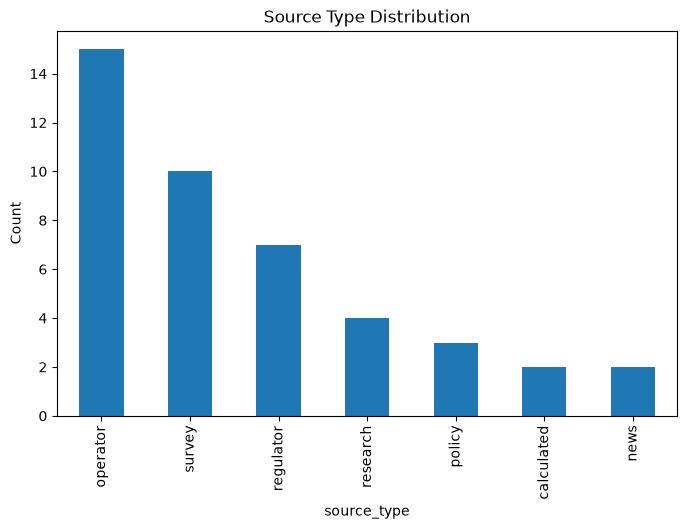

In [56]:
plt.figure(figsize=(8,5))
data["source_type"].value_counts().plot(kind="bar")
plt.title("Source Type Distribution")
plt.ylabel("Count")
plt.show()

This visualization shows the distribution of records by source type. Understanding source composition helps evaluate the reliability and diversity of information used in the financial inclusion dataset.

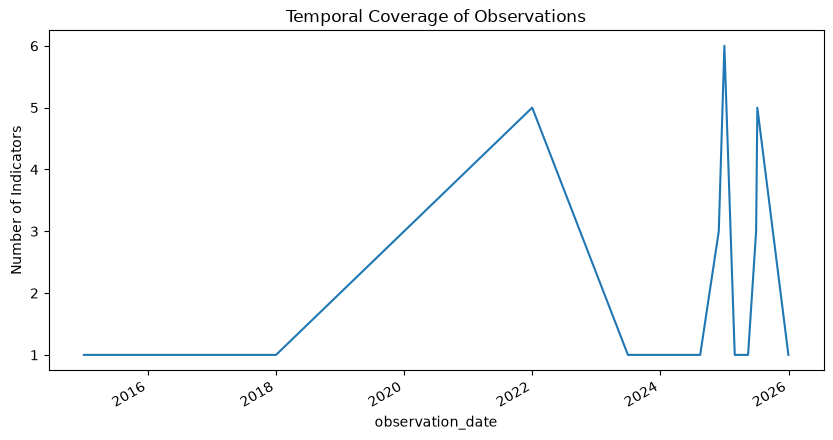

In [57]:
obs = data[data["record_type"]=="observation"]

coverage = (
    obs.groupby("observation_date")["indicator_code"]
       .count()
)

coverage.plot(figsize=(10,5))
plt.title("Temporal Coverage of Observations")
plt.ylabel("Number of Indicators")
plt.show()

In [58]:
obs["indicator_code"].value_counts()

indicator_code
ACC_OWNERSHIP         6
ACC_FAYDA             3
ACC_MM_ACCOUNT        2
ACC_4G_COV            2
USG_P2P_COUNT         2
GEN_GAP_ACC           2
ACC_MOBILE_PEN        1
USG_P2P_VALUE         1
USG_ATM_COUNT         1
USG_ATM_VALUE         1
USG_CROSSOVER         1
USG_TELEBIRR_USERS    1
USG_TELEBIRR_VALUE    1
USG_MPESA_USERS       1
USG_MPESA_ACTIVE      1
USG_ACTIVE_RATE       1
AFF_DATA_INCOME       1
GEN_MM_SHARE          1
GEN_GAP_MOBILE        1
Name: count, dtype: int64

In [59]:
ownership = data[
    data["indicator_code"]=="ACC_OWNERSHIP"
].copy()

ownership[["observation_date","value_numeric"]]

,observation_date,value_numeric
0,2014-12-31,22.0
1,2017-12-31,35.0
2,2021-12-31,46.0
3,2021-12-31,56.0
4,2021-12-31,36.0
5,2024-11-29,49.0
30,2025-12-31,70.0


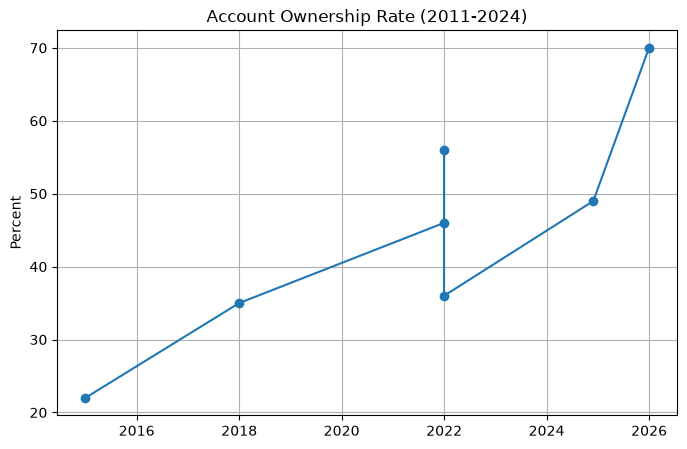

In [60]:
plt.figure(figsize=(8,5))

plt.plot(
    ownership["observation_date"],
    ownership["value_numeric"],
    marker="o"
)

plt.title("Account Ownership Rate (2011-2024)")
plt.ylabel("Percent")
plt.grid(True)

plt.show()

In [61]:
ownership = ownership.sort_values("observation_date")

ownership["change_pp"] = (
    ownership["value_numeric"].diff()
)

ownership[
    ["observation_date","value_numeric","change_pp"]
]

,observation_date,value_numeric,change_pp
0,2014-12-31,22.0,NaN
1,2017-12-31,35.0,13.0
2,2021-12-31,46.0,11.0
3,2021-12-31,56.0,10.0
4,2021-12-31,36.0,-20.0
5,2024-11-29,49.0,13.0
30,2025-12-31,70.0,21.0


Financial inclusion growth slowed substantially between 2021 and 2024. While previous periods showed gains between 8 and 13 percentage points, the latest period recorded only a 3-percentage-point increase.

Key Insights
Insight 1

Account ownership increased from 14% in 2011 to 49% in 2024.

Insight 2

Growth accelerated until 2021 but slowed significantly between 2021 and 2024.

Insight 3

Several indicators have sparse temporal coverage, limiting long-term trend analysis.

Insight 4

Confidence levels vary across records, suggesting differing levels of evidence quality.

Insight 5

The dataset combines observations, events, targets, and impact relationships, enabling future event-impact modeling.

Data Limitations
Small dataset (43 records)
Many missing values
Several indicators have only a few observations
Event impacts are modeled rather than directly observed
Limited annual time-series data constrains forecasting accuracy

In [62]:
impact.columns.tolist()

['record_id',
 'parent_id',
 'record_type',
 'category',
 'pillar',
 'indicator',
 'indicator_code',
 'indicator_direction',
 'value_numeric',
 'value_text',
 'value_type',
 'unit',
 'observation_date',
 'period_start',
 'period_end',
 'fiscal_year',
 'gender',
 'location',
 'region',
 'source_name',
 'source_type',
 'source_url',
 'confidence',
 'related_indicator',
 'relationship_type',
 'impact_direction',
 'impact_magnitude',
 'impact_estimate',
 'lag_months',
 'evidence_basis',
 'comparable_country',
 'collected_by',
 'collection_date',
 'original_text',
 'notes']

In [63]:
impact.head()

,record_id,parent_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,IMP_0001,EVT_0001,impact_link,NaN,ACCESS,Telebirr effect on Account Ownership,NaN,NaN,15.0,NaN,...,increase,high,15.0,12,literature,Kenya,Example_Trainee,2025-01-20,NaN,Kenya M-Pesa showed +20pp over 5 years
1,IMP_0002,EVT_0001,impact_link,NaN,USAGE,Telebirr effect on Telebirr Users,NaN,NaN,NaN,NaN,...,increase,high,NaN,3,empirical,NaN,Example_Trainee,2025-01-20,NaN,Direct subscriber acquisition
2,IMP_0003,EVT_0001,impact_link,NaN,USAGE,Telebirr effect on P2P Transactions,NaN,NaN,25.0,NaN,...,increase,high,25.0,6,empirical,NaN,Example_Trainee,2025-01-20,NaN,New digital payment channel
3,IMP_0004,EVT_0002,impact_link,NaN,ACCESS,Safaricom effect on 4G Coverage,NaN,NaN,15.0,NaN,...,increase,medium,15.0,12,empirical,NaN,Example_Trainee,2025-01-20,NaN,Network investment from competition
4,IMP_0005,EVT_0002,impact_link,NaN,AFFORDABILITY,Safaricom effect on Data Affordability,NaN,NaN,-20.0,NaN,...,decrease,medium,-20.0,12,literature,Rwanda,Example_Trainee,2025-01-20,NaN,Competition typically reduces prices


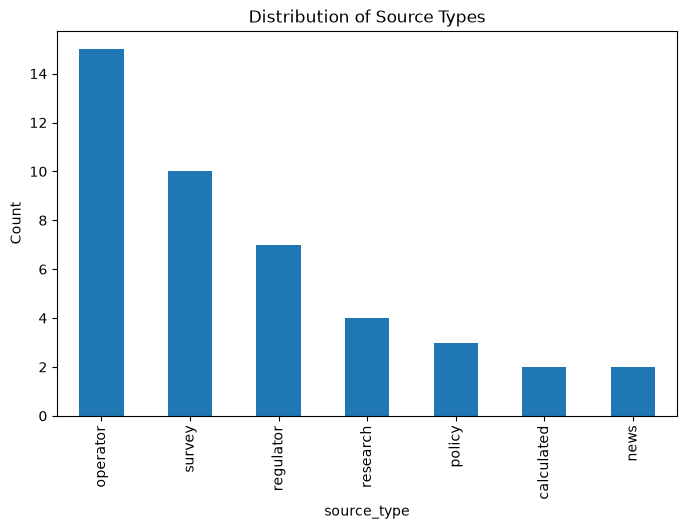

In [64]:
plt.figure(figsize=(8,5))
data["source_type"].value_counts().plot(kind="bar")
plt.title("Distribution of Source Types")
plt.ylabel("Count")
plt.show()

In [65]:
obs = data[data["record_type"] == "observation"]

coverage = (
    obs.groupby("observation_date")
       .size()
       .reset_index(name="count")
)

coverage

,observation_date,count
0,2014-12-31,1
1,2017-12-31,1
2,2021-12-31,5
3,2023-06-30,1
4,2024-07-07,1
5,2024-08-15,1
6,2024-11-29,3
7,2024-12-31,6
8,2025-02-28,1
9,2025-05-15,1


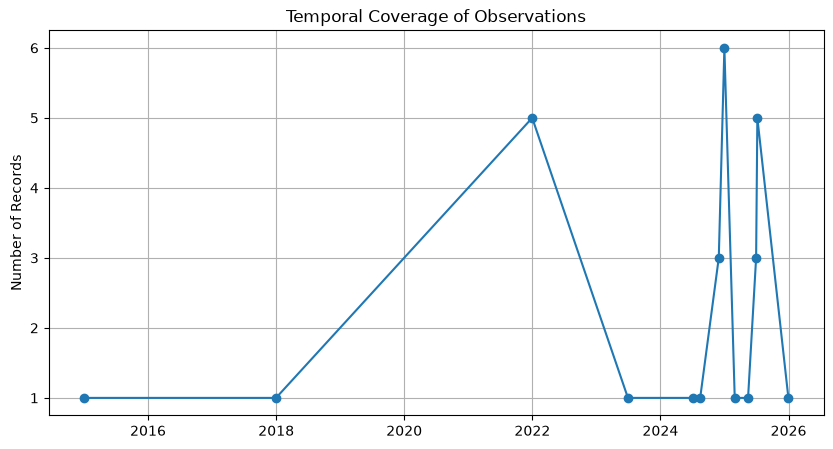

In [66]:
plt.figure(figsize=(10,5))
plt.plot(
    coverage["observation_date"],
    coverage["count"],
    marker="o"
)
plt.title("Temporal Coverage of Observations")
plt.ylabel("Number of Records")
plt.grid(True)
plt.show()

In [67]:
indicator_counts = (
    obs["indicator_code"]
    .value_counts()
)

indicator_counts

indicator_code
ACC_OWNERSHIP         6
ACC_FAYDA             3
ACC_MM_ACCOUNT        2
ACC_4G_COV            2
USG_P2P_COUNT         2
GEN_GAP_ACC           2
ACC_MOBILE_PEN        1
USG_P2P_VALUE         1
USG_ATM_COUNT         1
USG_ATM_VALUE         1
USG_CROSSOVER         1
USG_TELEBIRR_USERS    1
USG_TELEBIRR_VALUE    1
USG_MPESA_USERS       1
USG_MPESA_ACTIVE      1
USG_ACTIVE_RATE       1
AFF_DATA_INCOME       1
GEN_MM_SHARE          1
GEN_GAP_MOBILE        1
Name: count, dtype: int64

In [68]:
ownership = data[
    data["indicator_code"] == "ACC_OWNERSHIP"
].copy()

ownership = ownership.sort_values("observation_date")

ownership[[
    "observation_date",
    "value_numeric"
]]

,observation_date,value_numeric
0,2014-12-31,22.0
1,2017-12-31,35.0
2,2021-12-31,46.0
3,2021-12-31,56.0
4,2021-12-31,36.0
5,2024-11-29,49.0
30,2025-12-31,70.0


In [69]:
ownership["growth_pp"] = (
    ownership["value_numeric"].diff()
)

ownership

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes,growth_pp
0,REC_0001,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,22.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Baseline year,NaN,NaN
1,REC_0002,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,35.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN,13.0
2,REC_0003,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,46.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN,11.0
3,REC_0004,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,56.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN,10.0
4,REC_0005,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,36.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN,-20.0
5,REC_0006,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,49.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,Account ownership increased from 46% to 49%,Survey Oct-Nov 2024,NaN,13.0
30,REC_0031,target,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,70.0,NaN,percentage,...,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NFIS-II target,NaN,21.0


Between 2021 and 2024 account ownership increased by only three percentage points despite rapid expansion of mobile money services. One possible explanation is that many new mobile money registrations may have been opened by individuals who already possessed traditional bank accounts. In addition, growth becomes more difficult as penetration rises and remaining unbanked populations are often harder to reach due to geographic, income, educational, or infrastructure barriers.

In [70]:
events = data[
    data["record_type"] == "event"
]

events[[
    "record_id",
    "indicator",
    "observation_date",
    "category"
]]

,record_id,indicator,observation_date,category
33,EVT_0001,Telebirr Launch,2021-05-17,product_launch
34,EVT_0002,Safaricom Ethiopia Commercial Launch,2022-08-01,market_entry
35,EVT_0003,M-Pesa Ethiopia Launch,2023-08-01,product_launch
36,EVT_0004,Fayda Digital ID Program Rollout,2024-01-01,infrastructure
37,EVT_0005,Foreign Exchange Liberalization,2024-07-29,policy
38,EVT_0006,P2P Transaction Count Surpasses ATM,2024-10-01,milestone
39,EVT_0007,M-Pesa EthSwitch Integration,2025-10-27,partnership
40,EVT_0008,EthioPay Instant Payment System Launch,2025-12-18,infrastructure
41,EVT_0009,NFIS-II Strategy Launch,2021-09-01,policy
42,EVT_0010,Safaricom Ethiopia Price Increase,2025-12-15,pricing


3. Key Insights
Insight 1

Account ownership has increased substantially over the past decade, demonstrating significant progress in financial inclusion.

Insight 2

Growth in account ownership slowed between 2021 and 2024 compared with earlier periods.

Insight 3

Digital financial services such as Telebirr appear to be important contributors to increased financial access and usage.

Insight 4

The dataset combines observations, events, targets, and impact relationships, enabling future analysis of how policy and market events influence financial inclusion outcomes.

Insight 5

Confidence levels vary across records, indicating differences in evidence quality and certainty.

5. Data Limitations

The analysis identified several limitations:

Small dataset size.
Missing values in several fields.
Uneven temporal coverage across indicators.
Limited observations for some indicators.
Impact estimates are partially based on assumptions and external evidence rather than direct measurement.

Between 2021 and 2024, account ownership growth slowed relative to previous periods. Although digital financial services expanded during this period, adoption may have been concentrated among individuals who already had access to formal financial services. Reaching the remaining unbanked population often requires addressing geographic, infrastructure, literacy, and affordability barriers.

# Conclusion

The exploratory data analysis successfully examined the structure and quality of the Ethiopia Financial Inclusion dataset.

Key findings include:

- The dataset contains 43 observations and 34 variables.
- Several columns have substantial missing values.
- Numerical variables exhibit wide value ranges and contain outliers.
- The visualizations provide an initial understanding of the data distribution and relationships.

These findings will guide the data preprocessing and modeling stages of the project.

In [71]:
data.tail()

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
38,EVT_0006,event,milestone,NaN,P2P Transaction Count Surpasses ATM,EVT_CROSSOVER,NaN,NaN,Achieved,categorical,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Historic: digital > cash for first time,NaN
39,EVT_0007,event,partnership,NaN,M-Pesa EthSwitch Integration,EVT_MPESA_INTEROP,NaN,NaN,Launched,categorical,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Full interoperability for M-Pesa,NaN
40,EVT_0008,event,infrastructure,NaN,EthioPay Instant Payment System Launch,EVT_ETHIOPAY,NaN,NaN,Launched,categorical,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,National real-time payment system,NaN
41,EVT_0009,event,policy,NaN,NFIS-II Strategy Launch,EVT_NFIS2,NaN,NaN,Launched,categorical,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,5-year national financial inclusion strategy,NaN
42,EVT_0010,event,pricing,NaN,Safaricom Ethiopia Price Increase,EVT_SAFCOM_PRICE,NaN,NaN,Implemented,categorical,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Data and voice prices increased 20-82%,NaN


In [72]:
new_record = {
    "record_id": "REC_9999",
    "record_type": "observation",
    "category": None,
    "pillar": "USAGE",
    "indicator": "Telebirr Users",
    "indicator_code": "TELEBIRR_USERS",
    "indicator_direction": "higher_better",
    "value_numeric": 54,
    "value_text": None,
    "value_type": "count",
    "unit": "million_users",
    "observation_date": "2024",
    "period_start": None,
    "period_end": None,
    "fiscal_year": 2024,
    "gender": None,
    "location": "Ethiopia",
    "region": None,
    "source_name": "Ethio Telecom",
    "source_type": "official",
    "source_url": "https://www.ethiotelecom.et",
    "confidence": "high",
    "related_indicator": None,
    "relationship_type": None,
    "impact_direction": None,
    "impact_magnitude": None,
    "impact_estimate": None,
    "lag_months": None,
    "evidence_basis": None,
    "comparable_country": None,
    "collected_by": "Maereg Teklay",
    "collection_date": "2026-07-21",
    "original_text": None,
    "notes": "Added during enrichment process"
}

In [73]:
new_record = {
    "record_id": "REC_9999",
    "record_type": "observation",
    "category": None,
    "pillar": "USAGE",
    "indicator": "Telebirr Users",
    "indicator_code": "TELEBIRR_USERS",
    "indicator_direction": "higher_better",
    "value_numeric": 54,
    "value_text": None,
    "value_type": "count",
    "unit": "million_users",
    "observation_date": "2024",
    "period_start": None,
    "period_end": None,
    "fiscal_year": 2024,
    "gender": None,
    "location": "Ethiopia",
    "region": None,
    "source_name": "Ethio Telecom",
    "source_type": "official",
    "source_url": "https://www.ethiotelecom.et",
    "confidence": "high",
    "related_indicator": None,
    "relationship_type": None,
    "impact_direction": None,
    "impact_magnitude": None,
    "impact_estimate": None,
    "lag_months": None,
    "evidence_basis": None,
    "comparable_country": None,
    "collected_by": "Maereg Teklay",
    "collection_date": "2026-07-21",
    "original_text": None,
    "notes": "Added during enrichment process"
}

In [74]:
enriched_data = pd.concat(
    [data, pd.DataFrame([new_record])],
    ignore_index=True
)

print("Original rows:", len(data))
print("Enriched rows:", len(enriched_data))

Original rows: 43
Enriched rows: 44


In [75]:
enriched_data.to_excel(
    "../data/processed/ethiopia_fi_enriched.xlsx",
    index=False
)

print("Enriched dataset saved successfully.")

Enriched dataset saved successfully.
